## Qubit Power Fit

Global fit of a waveguide-qubit VNA power sweep and input-line attenuation, based on
[Hönigl-Decrinis et al., PRApplied 13, 024066 (2020)](https://doi.org/10.1103/PhysRevApplied.13.024066)
and the original `qubit-power-fits.ipynb`.

Helper functions live in `qubit_power_fit.py`; this notebook only sets parameters, looks at the results and saves them.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import qubit_power_fit as qpf

### Settings

* `REF_FILE = None` normalizes by the highest-power trace of the same sweep (qubit saturated). Its small residual reflection is included in the model through `p_norm`.
* Set `REF_FILE` to a sweep taken with the qubit detuned to normalize like the original notebook (then `p_norm` is not used).
* `USE_WEIGHTS` weights each power by its noise estimated from the trace itself, since the averages differ per power segment.

In [14]:
DATA_FILE = Path("qubit-power-sweep-5_58GHz_fine.json")
REF_FILE = Path("no-qubit-ref.json")            # e.g. Path("../../28-09-2026/1790630661-vna-power-sweep.json")
REF_POWER_DBM = None       # reference trace power when REF_FILE is None (None: highest power)

F_RANGE = (5.56, 5.60)     # GHz, fit window
P_REF = -30.0              # dBm, power at which omega_ref is reported
FIT_POWER_RANGE = None     # (min, max) dBm for the global fit, None: all
USE_WEIGHTS = True

ATT_POWER_RANGE = (-36, -20)  # dBm, points used for the W0 vs Win slope
R_ON_WINDOW_MHZ = 0.0         # >0: average Re r over f0 ± window instead of interpolating

OUT_DIR = Path("results") / DATA_FILE.stem
OUT_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    path = OUT_DIR / f"{DATA_FILE.stem}-{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", path)

### Load and normalize

In [15]:
sweep = qpf.load_sweep(DATA_FILE)

if REF_FILE is None:
    ref, p_norm = qpf.reference_trace(sweep, REF_POWER_DBM)
    ref_label = f"trace at {p_norm:g} dBm"
else:
    ref, p_norm = qpf.load_sweep(REF_FILE), None
    ref_label = str(REF_FILE)

t = qpf.normalize(sweep, ref)
r = 1 - t
re_r = r.real
noise = qpf.trace_noise(re_r)

print(f"file        : {sweep.path}  ({sweep.meta.get('date')} {sweep.meta.get('time')})")
print(f"shape       : {sweep.s21.shape}  (powers, frequencies)")
print(f"frequency   : {sweep.fghz[0]:.4f} - {sweep.fghz[-1]:.4f} GHz")
print(f"power       : {sweep.power_dbm.min():g} - {sweep.power_dbm.max():g} dBm")
print(f"attenuator  : {sweep.attenuator_db} dB (warm programmable)")
print(f"reference   : {ref_label}")
print()
for p, n, s in zip(sweep.power_dbm, sweep.averages, noise):
    print(f"{p:6.1f} dBm  averages = {n:4d}  noise(Re r) = {s:.4f}")

file        : qubit-power-sweep-5_58GHz_fine.json  (14-10-2026 06:59:48)
shape       : (51, 401)  (powers, frequencies)
frequency   : 5.4000 - 5.8000 GHz
power       : -50 - 0 dBm
attenuator  : 25.0 dB (warm programmable)
reference   : no-qubit-ref.json

 -50.0 dBm  averages =   50  noise(Re r) = 0.0724
 -49.0 dBm  averages =   50  noise(Re r) = 0.0562
 -48.0 dBm  averages =   50  noise(Re r) = 0.0525
 -47.0 dBm  averages =   50  noise(Re r) = 0.0431
 -46.0 dBm  averages =   50  noise(Re r) = 0.0380
 -45.0 dBm  averages =   50  noise(Re r) = 0.0406
 -44.0 dBm  averages =   50  noise(Re r) = 0.0319
 -43.0 dBm  averages =   50  noise(Re r) = 0.0293
 -42.0 dBm  averages =   50  noise(Re r) = 0.0225
 -41.0 dBm  averages =   50  noise(Re r) = 0.0212
 -40.0 dBm  averages =   50  noise(Re r) = 0.0182
 -39.0 dBm  averages =   50  noise(Re r) = 0.0177
 -38.0 dBm  averages =   50  noise(Re r) = 0.0172
 -37.0 dBm  averages =   50  noise(Re r) = 0.0114
 -36.0 dBm  averages =   50  noise(Re r) = 0.

### Quick look

saved results\qubit-power-sweep-5_58GHz_fine\qubit-power-sweep-5_58GHz_fine-abs-r.png


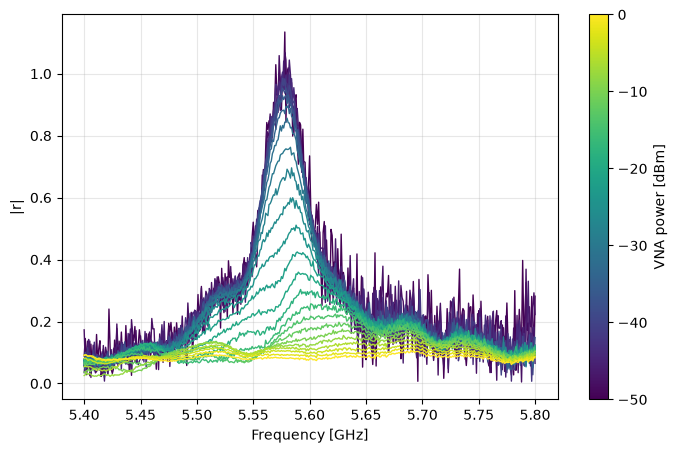

saved results\qubit-power-sweep-5_58GHz_fine\qubit-power-sweep-5_58GHz_fine-re-r-map.png


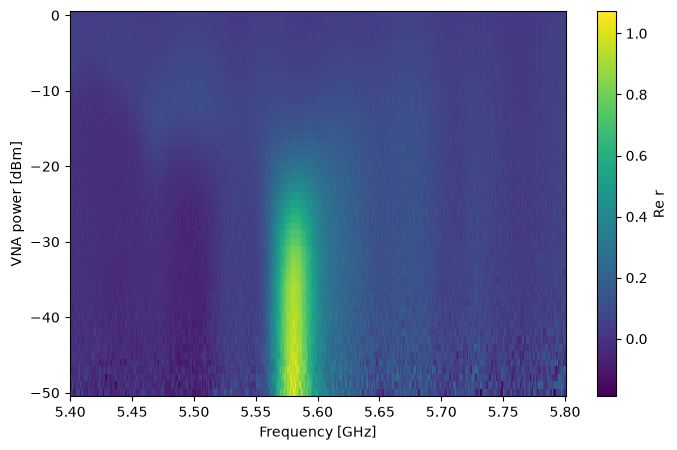

In [16]:
fig = qpf.plot_traces(sweep.fghz, sweep.power_dbm, np.abs(r), every=2, ylabel="|r|")
save(fig, "abs-r")
plt.show()

fig = qpf.plot_map(sweep.fghz, sweep.power_dbm, re_r)
save(fig, "re-r-map")
plt.show()

### Find Gamma1, Gamma2

All powers are fitted at once with $\Omega = \Omega_\mathrm{ref}\,10^{(P-P_\mathrm{ref})/20}$ (eq. 3) and a constant background on Re r.
Fano interference is not included yet.

In [17]:
fit = qpf.fit_power_sweep(
    sweep.fghz, sweep.power_dbm, re_r,
    p_ref=P_REF, p_norm=p_norm,
    f_range=F_RANGE, power_range=FIT_POWER_RANGE,
    sigma=noise if USE_WEIGHTS else None,
)
print(fit.report())

          f0 = 5.582562 ± 4.8e-05 GHz
          g1 = 26.93744 ± 0.12 MHz
          g2 = 14.29947 ± 0.087 MHz
   omega_ref = 10.01673 ± 0.063 MHz
  background = 0.03737724 ± 0.00035
   rms resid = 0.0376
    chi2_red = 10.4


saved results\qubit-power-sweep-5_58GHz_fine\qubit-power-sweep-5_58GHz_fine-fit.png


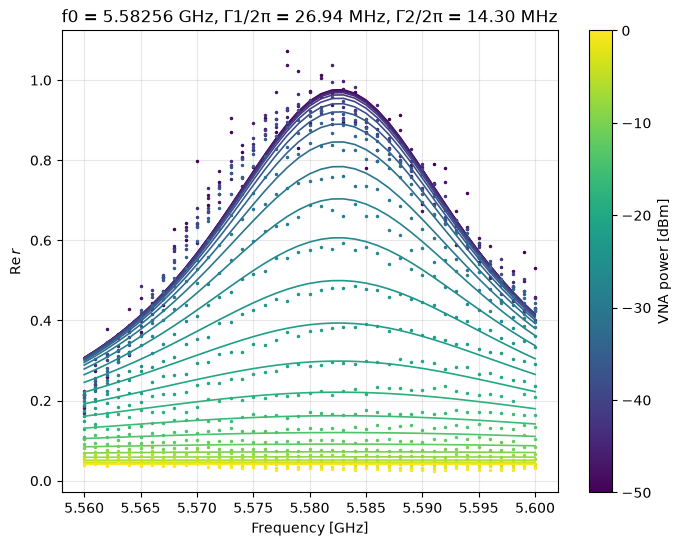

saved results\qubit-power-sweep-5_58GHz_fine\qubit-power-sweep-5_58GHz_fine-fit-residuals.png


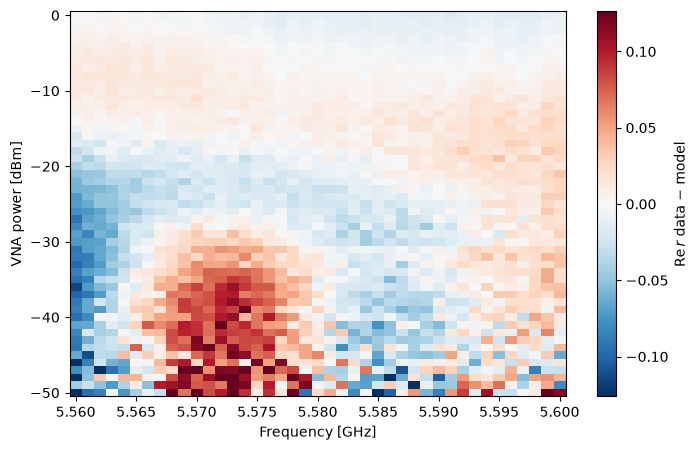

In [18]:
fig = qpf.plot_fit(fit, sweep.fghz, sweep.power_dbm, re_r, every=2)
fig.axes[0].set_title(f"f0 = {fit['f0']:.5f} GHz, Γ1/2π = {fit['g1']:.2f} MHz, Γ2/2π = {fit['g2']:.2f} MHz")
save(fig, "fit")
plt.show()

fig = qpf.plot_fit_residuals(fit, sweep.fghz, sweep.power_dbm, re_r)
save(fig, "fit-residuals")
plt.show()

### Get attenuation

$W_0$ at the qubit from $\Gamma_1$, $\Gamma_2$ and on-resonance Re r (eq. 4), then a linear fit of $W_0$ vs $W_\mathrm{in}$ through the origin; the slope is the attenuation.
As a cross-check, $W_0 = h f_0 \Omega_\mathrm{ref}^2 / 2\Gamma_1$ at $P_\mathrm{ref}$ gives the attenuation directly from the global fit.
The attenuation is from the VNA output port to the qubit and includes the warm programmable attenuator.

Input attenuation (slope fit)  = 103.42 dB
Input attenuation (omega_ref)  = 103.64 dB
  without 25 dB programmable attenuator: 78.42 dB / 78.64 dB
saved results\qubit-power-sweep-5_58GHz_fine\qubit-power-sweep-5_58GHz_fine-attenuation.png


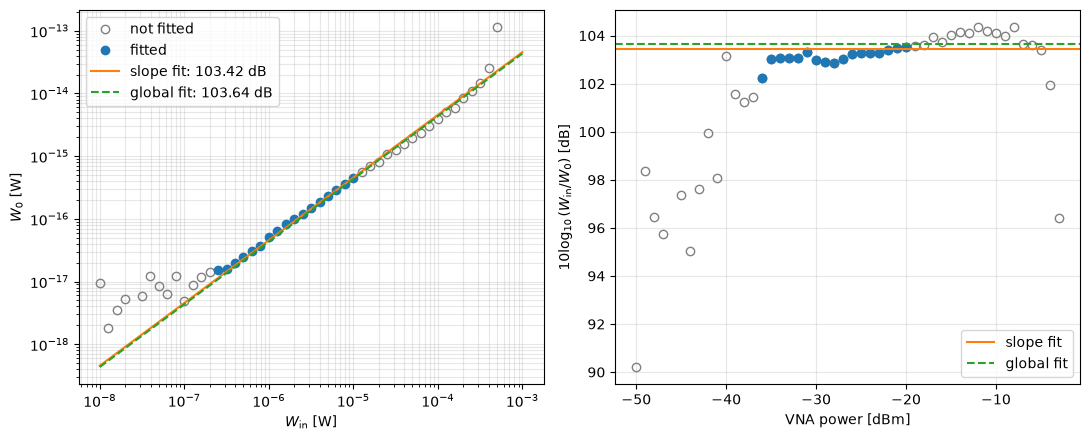

In [19]:
att = qpf.fit_attenuation(fit, sweep.fghz, sweep.power_dbm, re_r,
                          power_range=ATT_POWER_RANGE, window_mhz=R_ON_WINDOW_MHZ)

print(f"Input attenuation (slope fit)  = {att.attenuation_db:.2f} dB")
print(f"Input attenuation (omega_ref)  = {att.attenuation_fit_db:.2f} dB")
if sweep.attenuator_db is not None:
    print(f"  without {sweep.attenuator_db:g} dB programmable attenuator: "
          f"{att.attenuation_db - sweep.attenuator_db:.2f} dB / "
          f"{att.attenuation_fit_db - sweep.attenuator_db:.2f} dB")

fig = qpf.plot_attenuation(att)
save(fig, "attenuation")
plt.show()

### Save results

In [8]:
results = {
    "data_file": str(DATA_FILE),
    "reference": ref_label,
    "timestamp": sweep.meta.get("timestamp"),
    "programmable_attenuator_db": sweep.attenuator_db,
    "settings": {
        "f_range_ghz": F_RANGE, "p_ref_dbm": P_REF, "p_norm_dbm": p_norm,
        "fit_power_range_dbm": FIT_POWER_RANGE, "use_weights": USE_WEIGHTS,
        "att_power_range_dbm": ATT_POWER_RANGE, "r_on_window_mhz": R_ON_WINDOW_MHZ,
    },
    "fit": fit.to_dict(),
    "attenuation": att.to_dict(),
}
qpf.save_json(OUT_DIR / f"{DATA_FILE.stem}-fit-results.json", results)

WindowsPath('results/1791925995-qubit-power-sweep/1791925995-qubit-power-sweep-fit-results.json')